# KeraMine — Notebook 01: Audit Forensik, Data Cleaning & Multi-Level Basket Engineering
**Proyek UAS Analisis Data Mining (ADAMIN)** | **Dataset:** `datasetarule.xlsx` (Distribusi Keramik B2B)

Notebook ini dijalankan di **Google Colab** (`Runtime -> Run all`) dan melakukan:
1. **Inisialisasi & Penyaring Warning Colab (`StderrFilter`)** agar output bersih dari `DeprecationWarning` bawaan `jupyter_client`.
2. **Audit Forensik Mentah (`datasetarule.xlsx`):**
   - Mendeteksi baris kosong (*blank rows*), nilai kosong (*missing values*), transaksi retur/nol (`QTY <= 0`), inkonsistensi penulisan merek (`PISSCASO` vs `PICASSO`), serta anomali tabrakan nomor `NOTA` lintas toko.
   - Membuktikan secara empiris mengapa `NOTA` **tidak layak** dipakai sebagai keranjang belanja (*basket*).
3. **Pembersihan Data & Rekayasa Hierarki Item Multi-Level:**
   - Konversi kolom tanggal `TGL` ke ISO Date (`YYYY-MM-DD`), `year_month` (`YYYY-MM`), dan `year_week` (`YYYY-Www`).
   - Pemisahan transaksi retur/nol (`QTY <= 0`, 146 baris) ke `returns_log.csv` dari transaksi pembelian positif `transactions_clean.csv` (15.840 baris).
   - Ekstraksi dimensi `ukuran` via regex `(\d{2,3})\s*[xX×]\s*(\d{2,3})`, nama seri motif `seri`, dan gabungan `merk_ukuran`.
   - Pembangkitan `source_row_hash` (SHA-256) yang deterministik untuk idempotensi *upsert* ke **Supabase PostgreSQL**.
4. **Pembentukan & Evaluasi 5 Definisi Keranjang (*Basket Granularity*):**
   - Membandingkan `NOTA`, `Toko + Hari`, `Toko + Minggu`, **`Toko + Bulan` (Utama)**, dan `Toko Total`.
5. **Pengemasan Otomatis (`adamin_colab_01_outputs.zip`):**
   - Mengemas `transactions_clean.csv`, `returns_log.csv`, `store_profiles.json`, `cleaning_audit_summary.json`, `data_dictionary.md`, dan `basket_granularity_audit.png`, lalu memicu unduhan otomatis di Google Colab.

In [1]:
# ==============================================================================
# CELL 1: Setup Lingkungan, Filter DeprecationWarning Colab & Load Dataset
# ==============================================================================
import warnings
warnings.filterwarnings("ignore")

import sys

class StderrFilter:
    def __init__(self, original):
        self.original = original
    def write(self, text):
        if "jupyter_client" not in text and "DeprecationWarning" not in text and "utcnow" not in text:
            self.original.write(text)
    def flush(self):
        self.original.flush()

sys.stderr = StderrFilter(sys.stderr)

import os
import re
import json
import hashlib
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

IN_COLAB = "google.colab" in sys.modules
OUT_DIR = "adamin_colab_01_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# Cari lokasi datasetarule.xlsx secara otomatis, atau minta upload bila di Colab
candidate_paths = [
    "datasetarule.xlsx",
    "/content/datasetarule.xlsx",
    "../datasetarule.xlsx",
    "/content/drive/MyDrive/datasetarule.xlsx",
]
excel_path = next((p for p in candidate_paths if os.path.exists(p)), None)

if excel_path is None and IN_COLAB:
    from google.colab import files
    print("File datasetarule.xlsx belum ditemukan. Silakan pilih file datasetarule.xlsx untuk diunggah...")
    uploaded = files.upload()
    excel_path = next((k for k in uploaded.keys() if k.lower().endswith(".xlsx")), None)

assert excel_path is not None and os.path.exists(excel_path), (
    "datasetarule.xlsx tidak ditemukan! Letakkan di folder kerja Colab atau unggah saat diminta."
)

df_raw = pd.read_excel(excel_path, sheet_name=0)
print(f"Dataset berhasil dimuat dari: {excel_path}")
print(f"Dimensi terbaca pandas (baris x kolom): {df_raw.shape} (Excel sheet dimension A1:J16001 memiliki 14 trailing blank rows yang otomatis dipangkas reader)")
try:
    display(df_raw.head(5))
except NameError:
    print(df_raw.head(5))

Dataset berhasil dimuat dari: datasetarule.xlsx
Dimensi terbaca pandas (baris x kolom): (15986, 10) (Excel sheet dimension A1:J16001 memiliki 14 trailing blank rows yang otomatis dipangkas reader)


,NAMA,NAMABARA,TGL,NOTA,QTY,SATUAN,KODE,KODEBARA,POF,MERK
0,"SUN 3, TOKO",ROSANA BLUE 40X40,2022-08-01,JL*0368.4915,29,DUS,801,4115,ROBBY,PISSCASO
1,"4 PUTRI, TOKO",KRUING LIGHT COCO 50X50,2022-08-01,JL*0678.2871,91,DUS,923,5530,ROBBY,ANTARES
2,"REZEKI BARU, TOKO",CUBIC COKLAT 40X40,2022-08-01,JL*1434.0265,9,DUS,670,229,ROBBY,PISSCASO
3,"BUDI LUHUR JAYA, TOKO",PUTIH POLOS 50X50,2022-08-01,JL*0399.1313,62,DUS,579,4477,ROBBY,PISSCASO
4,"ANGGREK BANGUNAN, TOKO",LOTUS BIANCO 50X50,2022-08-01,JL*5045.1899,99,DUS,117,7582,DIAN,RAYMOND


## 2. Audit Forensik Data Mentah
Pada tahap ini kita memeriksa:
* Jumlah baris aktif vs baris kosong.
* Kelengkapan (*missing values*) pada seluruh 10 kolom.
* Transaksi retur/nol (`QTY <= 0`).
* Tabrakan nomor `NOTA` lintas toko/tanggal (`JL*7211.3746`).
* Inkonsistensi penulisan nama merek (`MERK`).

In [2]:
# ==============================================================================
# CELL 2: Audit Forensik Baris Kosong, Missing Values, Retur & Duplikasi NOTA
# ==============================================================================
raw_row_count = len(df_raw)
all_null_mask = df_raw.isna().all(axis=1)
blank_row_count = int(all_null_mask.sum())

df_active = df_raw.loc[~all_null_mask].copy().reset_index(drop=True)
df_active["excel_row"] = np.where(~all_null_mask)[0] + 2  # Baris 1 adalah header Excel

non_blank_count = len(df_active)
null_per_col_active = df_active.drop(columns=["excel_row"]).isna().sum().to_dict()
exact_duplicates_count = int(df_active.drop(columns=["excel_row"]).duplicated().sum())

# Cek tabrakan NOTA pada baris aktif
nota_counts = df_active["NOTA"].astype(str).str.strip().value_counts()
dup_notas = nota_counts[nota_counts > 1]
dup_nota_examples = []
for nota_val in dup_notas.index[:10]:
    sub = df_active[df_active["NOTA"].astype(str).str.strip() == nota_val]
    dup_nota_examples.append({
        "nota": nota_val,
        "count": int(len(sub)),
        "rows": sub[["excel_row", "NAMA", "NAMABARA", "TGL", "QTY", "MERK", "POF"]].astype(str).to_dict(orient="records"),
    })

# Cek distribusi QTY <= 0
qty_numeric = pd.to_numeric(df_active["QTY"], errors="coerce")
qty_lt_zero = int((qty_numeric < 0).sum())
qty_eq_zero = int((qty_numeric == 0).sum())
qty_le_zero = int((qty_numeric <= 0).sum())

# Cek ejaan MERK mentah
merk_raw_counts = df_active["MERK"].astype(str).str.strip().value_counts().sort_index().to_dict()

print("=== RINGKASAN AUDIT FORENSIK MENTAH ===")
print(f"Baris transaksi aktif terbaca : {non_blank_count:,} (baris kosong internal: {blank_row_count:,})")
print(f"Duplikat persis (seluruh kol) : {exact_duplicates_count:,}")
print(f"Unique NOTA (dari {non_blank_count:,})    : {df_active['NOTA'].nunique():,} (tabrakan NOTA: {len(dup_notas)})")
print(f"Transaksi QTY < 0             : {qty_lt_zero:,}")
print(f"Transaksi QTY == 0            : {qty_eq_zero:,}")
print(f"Total transaksi QTY <= 0      : {qty_le_zero:,}")
print("\nMissing values per kolom (pada baris aktif):")
print(pd.Series(null_per_col_active))
if dup_nota_examples:
    print("\nContoh tabrakan nomor NOTA pada toko/tanggal berbeda:")
    for ex in dup_nota_examples:
        print(f"  NOTA {ex['nota']} muncul {ex['count']}x ->", [(r["excel_row"], r["NAMA"], r["NAMABARA"]) for r in ex["rows"]])

assert non_blank_count == 15986, f"Ekspektasi 15.986 baris aktif, terbaca {non_blank_count}"
assert qty_le_zero == 146, f"Ekspektasi 146 baris QTY <= 0, terbaca {qty_le_zero}"
print("\n[PASS] Seluruh sanity assertion audit mentah terpenuhi.")

=== RINGKASAN AUDIT FORENSIK MENTAH ===
Baris transaksi aktif terbaca : 15,986 (baris kosong internal: 0)
Duplikat persis (seluruh kol) : 0
Unique NOTA (dari 15,986)    : 15,985 (tabrakan NOTA: 1)
Transaksi QTY < 0             : 0
Transaksi QTY == 0            : 146
Total transaksi QTY <= 0      : 146

Missing values per kolom (pada baris aktif):
NAMA        0
NAMABARA    0
TGL         0
NOTA        0
QTY         0
SATUAN      0
KODE        0
KODEBARA    0
POF         0
MERK        0
dtype: int64

Contoh tabrakan nomor NOTA pada toko/tanggal berbeda:
  NOTA JL*7211.3746 muncul 2x -> [('1425', 'EKA JAYA, TOKO', 'FRISTA BLUISH 25X40'), ('11276', 'DR BANGUNAN & GYPSUM', 'CRUSO GOLD 50X50')]

[PASS] Seluruh sanity assertion audit mentah terpenuhi.


## 3. Data Cleaning, Normalisasi & Ekstraksi Hierarki Multi-Level
Langkah pembersihan dan rekayasa fitur yang diterapkan:
1. **Standardisasi Teks:** Merapikan spasi berlebih pada `NAMA`, `NAMABARA`, `NOTA`, `SATUAN`, `POF`, `MERK`.
2. **Konversi Tanggal:** Mengubah kolom `TGL` menjadi tanggal ISO `YYYY-MM-DD`, `year_month` (`YYYY-MM`), dan `year_week` (`YYYY-Www`).
3. **Normalisasi Ejaan Merek (`merk_clean`):** Menyatukan typo `PISSCASO` $\rightarrow$ `PICASSO` (dengan tetap menyimpan `merk_raw` sebagai jejak audit). Kemungkinan singkatan `EFL` vs `EIFFEL` dicatat di log audit tanpa penggabungan paksa.
4. **Ekstraksi Hierarki Produk:**
   * `ukuran`: Dimensi keramik via regex `r"(\d{2,3})\s*[xX×]\s*(\d{2,3})"` (fallback `"NON_STD"` untuk 2 produk tanpa dimensi `NNXNN`, yaitu `GRANIT HITAM NA 6299` dan `GRANIT CREAM POLOS NA 703`).
   * `seri`: Nama seri motif utama (token pertama tervalidasi yang bukan angka/satuan/grade `KW`).
   * `merk_ukuran`: Gabungan `merk_clean + "_" + ukuran`.
5. **Pemisahan Baris Retur/Nol (`QTY <= 0`):** Disimpan terpisah ke `returns_log.csv` (146 baris) sehingga `transactions_clean.csv` (15.840 baris) hanya memuat pesanan pembelian positif.

In [3]:
# ==============================================================================
# CELL 3: Pembersihan, Ekstraksi Fitur & Pemisahan Transaksi Retur/Nol
# ==============================================================================
def clean_whitespace(series: pd.Series) -> pd.Series:
    return (
        series.astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

df = df_active.copy()
for col in ["NAMA", "NAMABARA", "NOTA", "SATUAN", "POF", "MERK"]:
    df[col] = clean_whitespace(df[col]).str.upper()

# Rename ke skema standar KeraMine (snake_case sesuai tabel keramine_transactions)
df = df.rename(columns={
    "NAMA": "nama_toko",
    "NAMABARA": "namabara",
    "NOTA": "nota",
    "SATUAN": "satuan",
    "KODE": "kode_toko",
    "KODEBARA": "kodebara",
    "POF": "pof",
    "MERK": "merk_raw",
    "QTY": "qty",
})

# Konversi TGL (mendukung serial numerik Excel maupun datetime64)
if pd.api.types.is_numeric_dtype(df["TGL"]):
    tgl_dt = pd.to_datetime(df["TGL"], unit="D", origin="1899-12-30")
else:
    tgl_dt = pd.to_datetime(df["TGL"])

df["tgl"] = tgl_dt.dt.strftime("%Y-%m-%d")
df["year_month"] = tgl_dt.dt.strftime("%Y-%m")
iso_cal = tgl_dt.dt.isocalendar()
df["year_week"] = iso_cal["year"].astype(str) + "-W" + iso_cal["week"].astype(str).str.zfill(2)

df["qty"] = pd.to_numeric(df["qty"], errors="raise").astype(int)
df["kode_toko"] = pd.to_numeric(df["kode_toko"], errors="coerce").astype("Int64")
df["kodebara"] = pd.to_numeric(df["kodebara"], errors="coerce").astype("Int64")

# Peta normalisasi ejaan merek yang terbukti typo
TYPO_MAP = {
    "PISSCASO": "PICASSO",
}
df["merk_clean"] = df["merk_raw"].replace(TYPO_MAP)

# Ekstraksi UKURAN via regex
SIZE_RE = re.compile(r"(\d{2,3})\s*[xX×]\s*(\d{2,3})")

def extract_ukuran(name: str) -> str:
    m = SIZE_RE.search(name)
    if m:
        return f"{int(m.group(1))}X{int(m.group(2))}"
    return "NON_STD"

SKIP_TOKENS = {"KW", "KW1", "KW2", "KW3", "KW4", "WD", "X", "MM", "CM", "M", "NA"}

def extract_seri(name: str) -> str:
    tokens = name.split()
    for tok in tokens:
        if tok in SKIP_TOKENS:
            continue
        if re.fullmatch(r"\d+", tok):
            continue
        if SIZE_RE.fullmatch(tok):
            continue
        if len(tok) >= 3 and re.match(r"^[A-Z]", tok):
            return tok
    return tokens[0] if tokens else "UNKNOWN"

df["ukuran"] = df["namabara"].apply(extract_ukuran)
df["seri"] = df["namabara"].apply(extract_seri)
df["merk_ukuran"] = df["merk_clean"] + "_" + df["ukuran"]
df["is_return"] = df["qty"] <= 0
df["source_batch"] = "historical_xlsx"

# Hash unik deterministik per baris Excel agar aman terhadap tabrakan NOTA
def make_row_hash(row) -> str:
    payload = (
        f"{int(row['excel_row'])}|{row['nota']}|{row['tgl']}|"
        f"{row['nama_toko']}|{row['namabara']}|{int(row['qty'])}|{row['merk_raw']}"
    )
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()[:32]

df["source_row_hash"] = df.apply(make_row_hash, axis=1)

ordered_cols = [
    "source_row_hash", "excel_row", "nota", "tgl", "year_month", "year_week",
    "nama_toko", "kode_toko", "namabara", "kodebara", "merk_raw", "merk_clean",
    "ukuran", "seri", "merk_ukuran", "qty", "satuan", "pof", "is_return", "source_batch"
]
df = df[ordered_cols]

df_returns = df[df["is_return"]].copy().reset_index(drop=True)
df_clean = df[~df["is_return"]].copy().reset_index(drop=True)

assert len(df_clean) + len(df_returns) == 15986
assert len(df_clean) == 15840, f"Ekspektasi 15.840 transaksi positif, terbaca {len(df_clean)}"
assert len(df_returns) == 146, f"Ekspektasi 146 transaksi retur/nol, terbaca {len(df_returns)}"
assert df["source_row_hash"].nunique() == len(df), "Hash baris harus 100% unik!"
assert df_clean["ukuran"].isna().sum() == 0
assert df_clean["seri"].isna().sum() == 0

print("=== RINGKASAN HASIL PEMBERSIHAN ===")
print(f"Rentang tanggal                : {df['tgl'].min()} s.d. {df['tgl'].max()}")
print(f"Transaksi pembelian positif    : {len(df_clean):,} baris (Total volume: {int(df_clean['qty'].sum()):,} DUS)")
print(f"Transaksi retur/nol dipisah    : {len(df_returns):,} baris")
print(f"Jumlah toko unik               : {df_clean['nama_toko'].nunique():,}")
print(f"Jumlah SKU (NAMABARA) unik     : {df_clean['namabara'].nunique():,}")
print(f"Jumlah SERI motif unik         : {df_clean['seri'].nunique():,}")
print(f"Jumlah MERK sebelum normalisasi: {df_clean['merk_raw'].nunique():,}")
print(f"Jumlah MERK setelah normalisasi: {df_clean['merk_clean'].nunique():,} (PISSCASO -> PICASSO digabung)")
print(f"Jumlah UKURAN unik             : {df_clean['ukuran'].nunique():,} -> {df_clean['ukuran'].value_counts().to_dict()}")
print(f"Jumlah MERK_UKURAN unik        : {df_clean['merk_ukuran'].nunique():,}")
try:
    display(df_clean.head(5))
except NameError:
    print(df_clean.head(5))

=== RINGKASAN HASIL PEMBERSIHAN ===
Rentang tanggal                : 2022-08-01 s.d. 2023-12-30
Transaksi pembelian positif    : 15,840 baris (Total volume: 794,064 DUS)
Transaksi retur/nol dipisah    : 146 baris
Jumlah toko unik               : 237
Jumlah SKU (NAMABARA) unik     : 438
Jumlah SERI motif unik         : 220
Jumlah MERK sebelum normalisasi: 22
Jumlah MERK setelah normalisasi: 21 (PISSCASO -> PICASSO digabung)
Jumlah UKURAN unik             : 8 -> {'40X40': 5109, '25X40': 3987, '50X50': 3607, '25X25': 2236, '25X50': 306, '60X60': 272, '20X40': 247, 'NON_STD': 76}
Jumlah MERK_UKURAN unik        : 168


,source_row_hash,excel_row,nota,tgl,year_month,year_week,nama_toko,kode_toko,namabara,kodebara,merk_raw,merk_clean,ukuran,seri,merk_ukuran,qty,satuan,pof,is_return,source_batch
0,b99a7f7824eaa15fb76ddf8b2380335a,2,JL*0368.4915,2022-08-01,2022-08,2022-W31,"SUN 3, TOKO",801,ROSANA BLUE 40X40,4115,PISSCASO,PICASSO,40X40,ROSANA,PICASSO_40X40,29,DUS,ROBBY,False,historical_xlsx
1,59a631c40fbb8e0b566fdcf369cc80b6,3,JL*0678.2871,2022-08-01,2022-08,2022-W31,"4 PUTRI, TOKO",923,KRUING LIGHT COCO 50X50,5530,ANTARES,ANTARES,50X50,KRUING,ANTARES_50X50,91,DUS,ROBBY,False,historical_xlsx
2,f732c1aa47b8d7bcd06bb83b114a5129,4,JL*1434.0265,2022-08-01,2022-08,2022-W31,"REZEKI BARU, TOKO",670,CUBIC COKLAT 40X40,229,PISSCASO,PICASSO,40X40,CUBIC,PICASSO_40X40,9,DUS,ROBBY,False,historical_xlsx
3,7aa1474f98fc2088d12d4146afc86346,5,JL*0399.1313,2022-08-01,2022-08,2022-W31,"BUDI LUHUR JAYA, TOKO",579,PUTIH POLOS 50X50,4477,PISSCASO,PICASSO,50X50,PUTIH,PICASSO_50X50,62,DUS,ROBBY,False,historical_xlsx
4,0292f65361795606bad1240702dbe0be,6,JL*5045.1899,2022-08-01,2022-08,2022-W31,"ANGGREK BANGUNAN, TOKO",117,LOTUS BIANCO 50X50,7582,RAYMOND,RAYMOND,50X50,LOTUS,RAYMOND_50X50,99,DUS,DIAN,False,historical_xlsx


## 4. Evaluasi Empiris 5 Definisi Keranjang (*Basket Granularity Audit*)
Di sini kita membuktikan secara kuantitatif mengapa `NOTA` gagal menjadi keranjang transaksi B2B dan bagaimana agregasi `Toko + Bulan` menghasilkan **>92% keranjang multi-item**.

Perbandingan 5 Definisi Keranjang pada 15.840 Transaksi Positif:


,definisi_keranjang,total_basket,multi_item_basket,rasio_multi_item_pct,rata_rata_item,maks_item
0,NOTA (Faktur Baris),15839,1,0.01,1.00,2
1,Toko + Hari,14874,927,6.23,1.06,4
2,Toko + Minggu,10475,4032,38.49,1.51,6
3,Toko + Bulan,3949,3654,92.53,3.99,12
4,Toko Total (17 Bulan),237,237,100.00,62.03,83


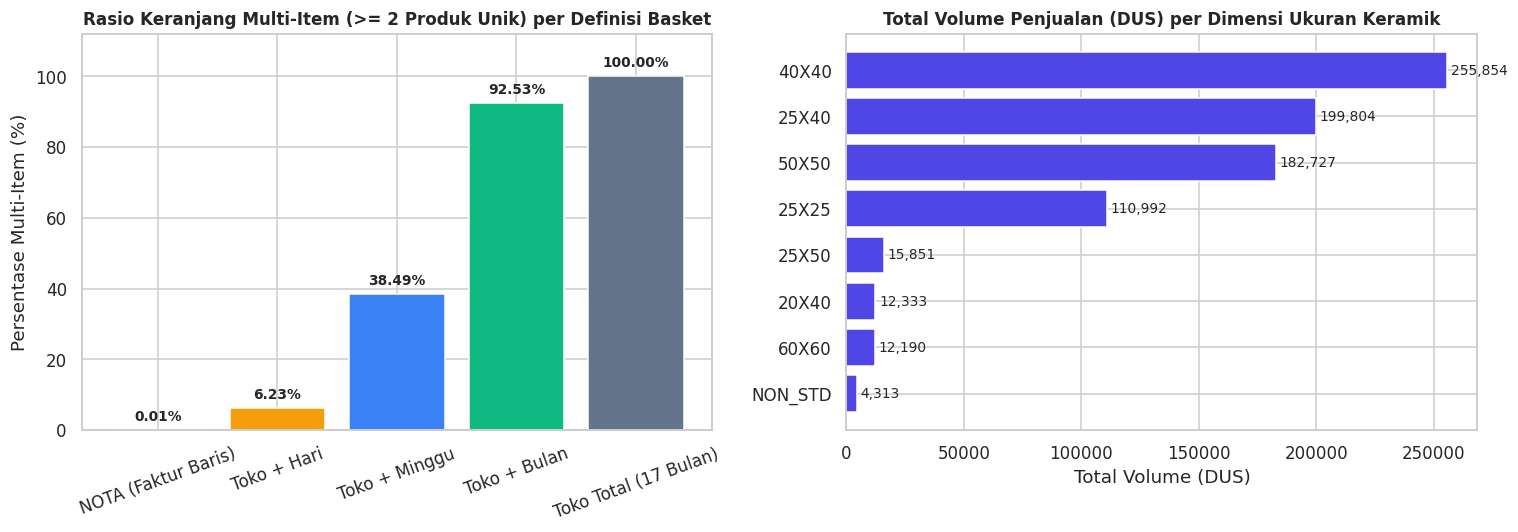

In [4]:
# ==============================================================================
# CELL 4: Audit Perbandingan 5 Definisi Keranjang & Visualisasi EDA
# ==============================================================================
basket_defs = {
    "NOTA (Faktur Baris)": df_clean["nota"],
    "Toko + Hari": df_clean["nama_toko"] + "|" + df_clean["tgl"],
    "Toko + Minggu": df_clean["nama_toko"] + "|" + df_clean["year_week"],
    "Toko + Bulan": df_clean["nama_toko"] + "|" + df_clean["year_month"],
    "Toko Total (17 Bulan)": df_clean["nama_toko"],
}

granularity_rows = []
for label, key_series in basket_defs.items():
    tmp = pd.DataFrame({"basket_id": key_series, "item": df_clean["namabara"]})
    sizes = tmp.groupby("basket_id")["item"].nunique()
    total_b = int(len(sizes))
    multi_b = int((sizes >= 2).sum())
    granularity_rows.append({
        "definisi_keranjang": label,
        "total_basket": total_b,
        "multi_item_basket": multi_b,
        "rasio_multi_item_pct": round(multi_b * 100.0 / total_b, 2),
        "rata_rata_item": round(float(sizes.mean()), 2),
        "maks_item": int(sizes.max()),
    })

df_granularity = pd.DataFrame(granularity_rows)
print("Perbandingan 5 Definisi Keranjang pada 15.840 Transaksi Positif:")
try:
    display(df_granularity)
except NameError:
    print(df_granularity)

# Visualisasi 2 panel: Rasio Multi-Item per Definisi Keranjang & Volume DUS per Ukuran
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ["#EF4444", "#F59E0B", "#3B82F6", "#10B981", "#64748B"]
bars = axes[0].bar(df_granularity["definisi_keranjang"], df_granularity["rasio_multi_item_pct"], color=colors)
axes[0].set_title("Rasio Keranjang Multi-Item (>= 2 Produk Unik) per Definisi Basket", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Persentase Multi-Item (%)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].set_ylim(0, 112)
for b in bars:
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, h + 1.8, f"{h:.2f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")

size_qty = df_clean.groupby("ukuran")["qty"].sum().sort_values(ascending=True)
axes[1].barh(size_qty.index, size_qty.values, color="#4F46E5")
axes[1].set_title("Total Volume Penjualan (DUS) per Dimensi Ukuran Keramik", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Total Volume (DUS)")
for idx, val in enumerate(size_qty.values):
    axes[1].text(val + 1500, idx, f"{int(val):,}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "basket_granularity_audit.png"), bbox_inches="tight")
plt.show()

## 5. Pembangunan Profil Toko (`store_profiles.json`), Log Audit & Ekspor ZIP Artefak
Seluruh artefak bersih disimpan dan dibungkus ke dalam **`adamin_colab_01_outputs.zip`** untuk diserahkan kembali ke repositori `data/clean/`.

In [5]:
# ==============================================================================
# CELL 5: Ekspor Artefak Bersih & Pengemasan Otomatis adamin_colab_01_outputs.zip
# ==============================================================================
clean_csv_path = os.path.join(OUT_DIR, "transactions_clean.csv")
returns_csv_path = os.path.join(OUT_DIR, "returns_log.csv")
df_clean.to_csv(clean_csv_path, index=False)
df_returns.to_csv(returns_csv_path, index=False)

# Profil 237 toko pelanggan (sinkron dengan tabel keramine_store_profiles)
store_profiles = []
return_counts_by_store = df_returns.groupby("nama_toko").size().to_dict()

for store_name, grp in df_clean.groupby("nama_toko"):
    top_merks = grp.groupby("merk_clean")["qty"].sum().sort_values(ascending=False).head(5)
    top_seris = grp.groupby("seri")["qty"].sum().sort_values(ascending=False).head(5)
    top_ukurans = grp.groupby("ukuran")["qty"].sum().sort_values(ascending=False).head(5)
    dom_pof = grp["pof"].mode().iloc[0] if not grp["pof"].mode().empty else "UNKNOWN"
    kode_val = int(grp["kode_toko"].dropna().iloc[0]) if not grp["kode_toko"].dropna().empty else None

    store_profiles.append({
        "nama_toko": store_name,
        "kode_toko": kode_val,
        "dominant_pof": dom_pof,
        "total_transactions": int(len(grp)),
        "total_baskets_month": int(grp["year_month"].nunique()),
        "total_unique_skus": int(grp["namabara"].nunique()),
        "total_qty_dus": float(grp["qty"].sum()),
        "return_count": int(return_counts_by_store.get(store_name, 0)),
        "top_merks": [{"name": k, "qty_dus": float(v)} for k, v in top_merks.items()],
        "top_seris": [{"name": k, "qty_dus": float(v)} for k, v in top_seris.items()],
        "top_ukurans": [{"name": k, "qty_dus": float(v)} for k, v in top_ukurans.items()],
    })

store_profiles_path = os.path.join(OUT_DIR, "store_profiles.json")
with open(store_profiles_path, "w", encoding="utf-8") as f:
    json.dump(store_profiles, f, ensure_ascii=False, indent=2)

pof_summary = (
    df_clean.groupby("pof")
    .agg(transactions=("nota", "count"), total_qty_dus=("qty", "sum"), unique_stores=("nama_toko", "nunique"))
    .reset_index()
    .to_dict(orient="records")
)

audit_summary = {
    "dataset_source": "datasetarule.xlsx",
    "excel_sheet_dimension_note": "A1:J16001 (16.000 baris data XML dengan 14 trailing blank rows yang dipangkas reader -> 15.986 baris aktif)",
    "active_rows_total": non_blank_count,
    "blank_rows_internal": blank_row_count,
    "exact_duplicates": exact_duplicates_count,
    "duplicate_nota_collisions": dup_nota_examples,
    "positive_transactions_count": int(len(df_clean)),
    "returns_zero_qty_count": int(len(df_returns)),
    "date_range": {"min": df_clean["tgl"].min(), "max": df_clean["tgl"].max(), "unique_months": int(df_clean["year_month"].nunique())},
    "total_qty_dus_positive": float(df_clean["qty"].sum()),
    "avg_qty_dus_per_line": round(float(df_clean["qty"].mean()), 2),
    "median_qty_dus_per_line": float(df_clean["qty"].median()),
    "unique_counts": {
        "stores": int(df_clean["nama_toko"].nunique()),
        "skus": int(df_clean["namabara"].nunique()),
        "merks_raw": int(df_clean["merk_raw"].nunique()),
        "merks_clean": int(df_clean["merk_clean"].nunique()),
        "ukurans": int(df_clean["ukuran"].nunique()),
        "seris": int(df_clean["seri"].nunique()),
        "merk_ukurans": int(df_clean["merk_ukuran"].nunique()),
        "pofs": int(df_clean["pof"].nunique()),
    },
    "typo_normalization": {"PISSCASO_to_PICASSO_rows": int((df_active["MERK"].astype(str).str.strip().str.upper() == "PISSCASO").sum())},
    "non_standard_size_skus": sorted(df_clean.loc[df_clean["ukuran"] == "NON_STD", "namabara"].unique().tolist()),
    "pof_summary": pof_summary,
    "basket_granularity_comparison": granularity_rows,
    "null_counts_active_raw": {k: int(v) for k, v in null_per_col_active.items()},
}

audit_path = os.path.join(OUT_DIR, "cleaning_audit_summary.json")
with open(audit_path, "w", encoding="utf-8") as f:
    json.dump(audit_summary, f, ensure_ascii=False, indent=2)

dict_md = f'''# Data Dictionary: KeraMine Clean Artifacts

Dihasilkan oleh `notebooks/01_data_cleaning_basket_engineering.ipynb`.
- **Total baris aktif terbaca (`datasetarule.xlsx`):** {non_blank_count:,} baris.
- **Transaksi positif (`transactions_clean.csv`):** {len(df_clean):,} baris (`QTY > 0`).
- **Transaksi retur/nol (`returns_log.csv`):** {len(df_returns):,} baris (`QTY <= 0`).
- **Rentang tanggal:** {df_clean['tgl'].min()} s.d. {df_clean['tgl'].max()}.

## Kolom pada `transactions_clean.csv` & `returns_log.csv`
| Kolom | Tipe | Deskripsi |
|---|---|---|
| `source_row_hash` | string | Hash SHA-256 (32 hex) unik per baris Excel untuk idempotensi database |
| `excel_row` | int | Nomor baris sumber pada `datasetarule.xlsx` |
| `nota` | string | Nomor faktur pengiriman (non-unik: terdeteksi 1 tabrakan `JL*7211.3746`) |
| `tgl` | date | Tanggal ISO `YYYY-MM-DD` |
| `year_month` | string | Kunci periode bulanan `YYYY-MM` (unit basket utama bersama `nama_toko`) |
| `year_week` | string | Kunci periode mingguan ISO `YYYY-Www` |
| `nama_toko` | string | Nama toko bangunan pelanggan B2B (237 toko) |
| `kode_toko` | int | Kode numerik toko |
| `namabara` | string | Nama SKU produk lengkap (438 SKU) |
| `kodebara` | int | Kode numerik barang |
| `merk_raw` | string | Merek mentah sebelum normalisasi (22 label) |
| `merk_clean` | string | Merek bersih (21 merek setelah normalisasi `PISSCASO` -> `PICASSO`) |
| `ukuran` | string | Dimensi ukuran keramik hasil ekstraksi regex (`40X40`, `25X40`, ..., `NON_STD`) |
| `seri` | string | Nama seri motif utama (220 seri) |
| `merk_ukuran` | string | Gabungan `merk_clean + '_' + ukuran` |
| `qty` | int | Jumlah kardus keramik (`DUS`) |
| `satuan` | string | Satuan kemasan (`DUS`) |
| `pof` | string | Nama tenaga penjual (`DIAN`, `ROBBY`, `JONI`, `BARI`) |
| `is_return` | bool | `True` jika `qty <= 0`, `False` jika `qty > 0` |
| `source_batch` | string | Penanda asal batch data (`historical_xlsx` / `n8n_live`) |
'''
dict_path = os.path.join(OUT_DIR, "data_dictionary.md")
with open(dict_path, "w", encoding="utf-8") as f:
    f.write(dict_md)

zip_filename = "adamin_colab_01_outputs.zip"
with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zf:
    for fname in [
        "transactions_clean.csv",
        "returns_log.csv",
        "store_profiles.json",
        "cleaning_audit_summary.json",
        "data_dictionary.md",
        "basket_granularity_audit.png",
    ]:
        fpath = os.path.join(OUT_DIR, fname)
        assert os.path.exists(fpath), f"File {fpath} gagal dibuat!"
        zf.write(fpath, arcname=fname)

print(f"\n[SELESAI] Paket {zip_filename} ({os.path.getsize(zip_filename)/1024:.1f} KB) berhasil dibuat!")
if IN_COLAB:
    from google.colab import files
    files.download(zip_filename)
    print("Silakan letakkan adamin_colab_01_outputs.zip ke folder notebooks/ pada proyek ADAMIN Anda.")


[SELESAI] Paket adamin_colab_01_outputs.zip (1042.0 KB) berhasil dibuat!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Silakan letakkan adamin_colab_01_outputs.zip ke folder notebooks/ pada proyek ADAMIN Anda.
